# A16 · 底价、填充率与供需效用

先修：公用31–34；A15。

证据类型：**明确构造机制实验（非真实广告日志）**。本章不声称工业系统复现或线上收益。

学习顺序：先预测 → 只改一个变量 → 运行 → 解释结果。

## 问题与输入输出契约

构造2000场拍卖、每场3个独立U(0,2)估值且诚实报价，二价与统一reserve；支付=max(reserve,第二高报价)，最高报价不足底价则流拍。同一固定报价矩阵扫描底价，分别计算每请求收入、填充率、赢家效用，不能把未成交请求从收入分母删除。

运行前预测：本章只改变的变量会使哪一项结果变化？哪些不变量必须保持？

In [1]:
from pathlib import Path
import sys
root=Path.cwd()
if not (root/'reclab').exists(): root=root.parent
if str(root) not in sys.path: sys.path.insert(0,str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab import ads_curriculum as ac

## 运行单变量对照

输入是源码中可见的小型构造数据，输出单位和约束按上文定义。运行断言核验数学与账本。

,reserve,fill,revenue,utility
0,0.0,1.0000,0.990359,0.495017
1,0.5,0.9835,1.011443,0.467694
2,1.0,0.8665,1.052319,0.333432
3,1.5,0.5665,0.875826,0.128916
4,2.0,0.0000,0.000000,0.000000


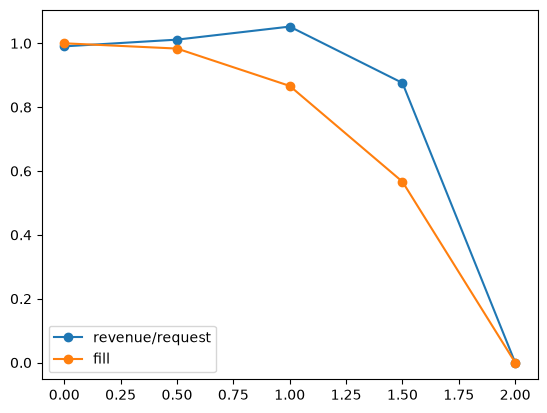

In [2]:
rows=ac.reserves();display(pd.DataFrame(rows))
plt.plot([r['reserve'] for r in rows],[r['revenue'] for r in rows],marker='o',label='revenue/request');plt.plot([r['reserve'] for r in rows],[r['fill'] for r in rows],marker='o',label='fill');plt.legend();plt.show()
assert rows[-1]['fill']==0
assert all(rows[i]['fill']>=rows[i+1]['fill'] for i in range(len(rows)-1))

## 解释与局限

底价过高会使填充归零；收入与填充不一定同步。U(0,2)的规则分布理论保留价是1，但有限样本网格只是此假设下的验证，不能据此设置真实平台价格，且报价策略可能随机制变化。

## 查看源码，再做练习

只改估值分布为偏态，保持随机数配对；解释为何历史输标截尾价格会妨碍直接拟合完整估值分布。

In [3]:
import inspect
print(inspect.getsource(ac.reserves))

def reserves():
    bids=np.random.default_rng(42).uniform(0,2,(2000,3)); order=np.sort(bids,axis=1)
    rows=[]
    for reserve in (0.,.5,1.,1.5,2.):
        win=order[:,-1]>=reserve; pay=np.where(win,np.maximum(reserve,order[:,-2]),0)
        utility=np.where(win,order[:,-1]-pay,0)
        assert np.all(utility>=-1e-12)
        rows.append(dict(reserve=reserve,fill=float(win.mean()),revenue=float(pay.mean()),utility=float(utility.mean())))
    return rows



## 来源与下一步

A-RTB 150–163页。这是Lab自行设计的小实验，不复制讲义全文。

[GitHub中文单章](https://github.com/SocratesClub/ccrbook/blob/6dbd5650f2adc6e257e5bd5d156bc50a72560ee9/slides/Chapter%208%20%E8%AE%A1%E7%AE%97%E5%B9%BF%E5%91%8A.pptx) · [作者RTB讲义](https://wnzhang.net/slides/cikm-16-rtb-full.pdf)。中文PPT不是现代广告工程全套课；不将历史平台机制描述当作当前市场事实。

完成练习后回到广告学习路径，继续下一语义单元。